# Data Wrangling: Finding and Removing Duplicates

Part of my IBM Data Analyst Capstone project. In this notebook I check the developer survey data for duplicate records, separate true duplicates from respondents who simply gave the same answers, and remove the true duplicates.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

## 1. Load the data

In [2]:
# Load the dataset directly from the URL
file_path = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/VYPrOu0Vs3I0hKLLjiPGrA/survey-data-with-duplicate.csv"
df = pd.read_csv(file_path)

# Display the first few rows
print(df.head())

   ResponseId                      MainBranch                 Age  \
0           1  I am a developer by profession  Under 18 years old   
1           2  I am a developer by profession     35-44 years old   
2           3  I am a developer by profession     45-54 years old   
3           4           I am learning to code     18-24 years old   
4           5  I am a developer by profession     18-24 years old   

            Employment RemoteWork   Check  \
0  Employed, full-time     Remote  Apples   
1  Employed, full-time     Remote  Apples   
2  Employed, full-time     Remote  Apples   
3   Student, full-time        NaN  Apples   
4   Student, full-time        NaN  Apples   

                                    CodingActivities  \
0                                              Hobby   
1  Hobby;Contribute to open-source projects;Other...   
2  Hobby;Contribute to open-source projects;Other...   
3                                                NaN   
4                                 

## 2. Identify duplicate rows
Count fully duplicated rows (every column identical) and display examples.

In [3]:
# 1. Count fully duplicated rows (every column identical)
dup_count = df.duplicated().sum()
print("Number of duplicate rows:", dup_count)

# 2. Show a few duplicates (keep=False shows the original and its copies together)
duplicates = df[df.duplicated(keep=False)].sort_values(by="ResponseId")
print(duplicates.head(10))

Number of duplicate rows: 20       ResponseId                      MainBranch                 Age  \
0               1  I am a developer by profession  Under 18 years old   
65437           1  I am a developer by profession  Under 18 years old   
65438           2  I am a developer by profession     35-44 years old   
1               2  I am a developer by profession     35-44 years old   
2               3  I am a developer by profession     45-54 years old   
65439           3  I am a developer by profession     45-54 years old   
65440           4           I am learning to code     18-24 years old   
3               4           I am learning to code     18-24 years old   
4               5  I am a developer by profession     18-24 years old   
65441           5  I am a developer by profession     18-24 years old   

                Employment RemoteWork   Check  \
0      Employed, full-time     Remote  Apples   
65437  Employed, full-time     Remote  Apples   
65438  Employed, full

## 3. Analyse shared response patterns
Check whether respondents who share the same MainBranch, Employment and RemoteWork answers are duplicates, or just different people with similar answers.

In [4]:
pattern_cols = ['MainBranch', 'Employment', 'RemoteWork']

# 1. Count how many respondents share each answer combination
pattern_counts = (df.groupby(pattern_cols, dropna=False)
                    .size()
                    .reset_index(name='Count')
                    .sort_values('Count', ascending=False))
print(pattern_counts.head(10))

# Rows whose pattern appears more than once
shared = df[df.duplicated(subset=pattern_cols, keep=False)]
print("Respondents sharing a pattern:", len(shared))

# 2. Which other columns have identical values within the most common pattern group?
top = pattern_counts.iloc[0]
top_group = df[(df['MainBranch'] == top['MainBranch']) &
               (df['Employment'] == top['Employment']) &
               (df['RemoteWork'] == top['RemoteWork'])]

other_cols = [c for c in df.columns if c not in pattern_cols + ['ResponseId']]
share_of_top_value = top_group[other_cols].apply(
    lambda s: s.value_counts(normalize=True, dropna=False).iloc[0])
print(share_of_top_value.sort_values(ascending=False).head(10))

                                            MainBranch  \
0                       I am a developer by profession   
2                       I am a developer by profession   
1                       I am a developer by profession   
82                      I am a developer by profession   
9                       I am a developer by profession   
244                              I am learning to code   
280  I am not primarily a developer, but I write co...   
111                     I am a developer by profession   
456                        I code primarily as a hobby   
7                       I am a developer by profession   

                                            Employment  \
0                                  Employed, full-time   
2                                  Employed, full-time   
1                                  Employed, full-time   
82   Independent contractor, freelancer, or self-em...   
9    Employed, full-time;Independent contractor, fr...   
244          

## 4. Visualise shared response patterns

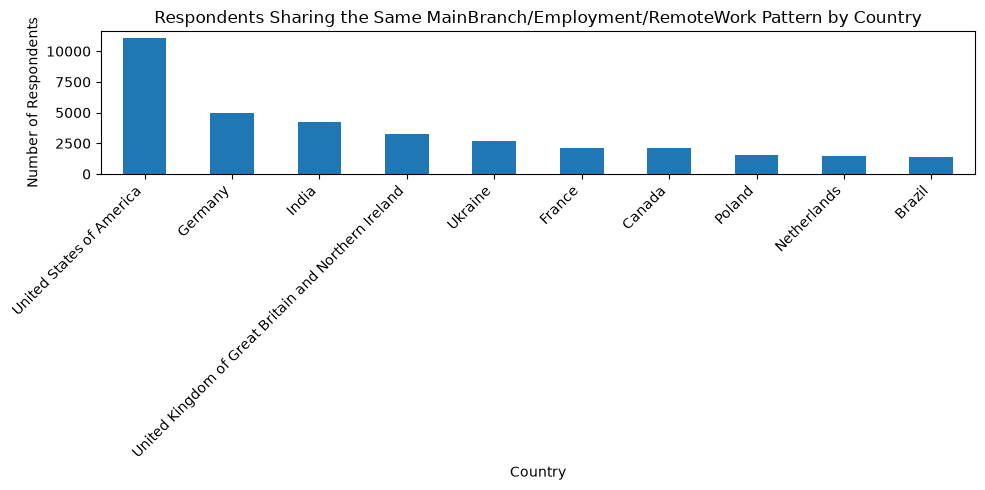

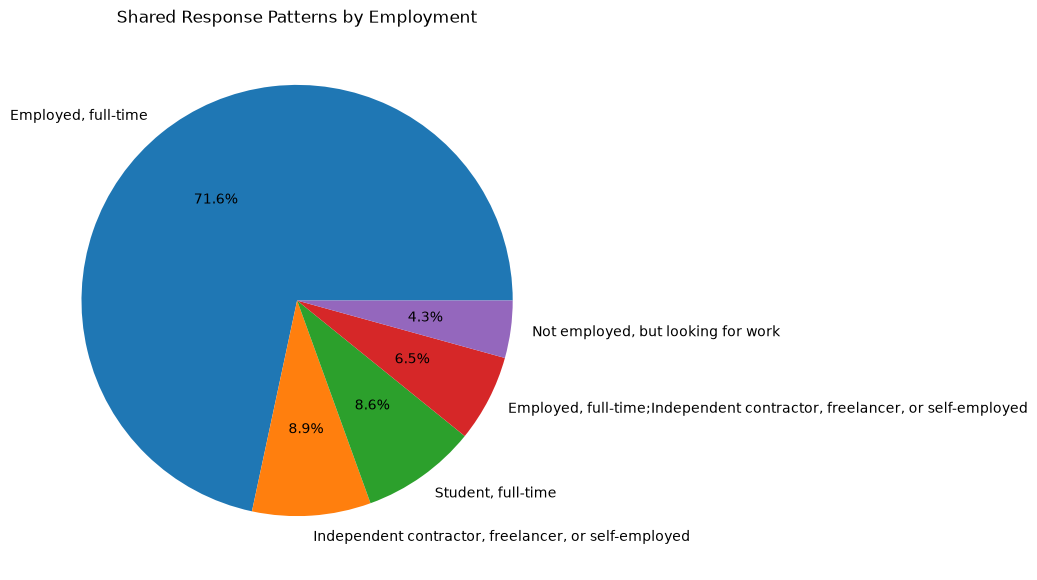

In [5]:
# Shared-pattern respondents by Country (top 10)
shared['Country'].value_counts().head(10).plot(kind='bar', figsize=(10,5))
plt.title("Respondents Sharing the Same MainBranch/Employment/RemoteWork Pattern by Country")
plt.xlabel("Country")
plt.ylabel("Number of Respondents")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# Shared-pattern respondents by Employment (top 5, pie chart)
shared['Employment'].value_counts().head(5).plot(kind='pie', autopct='%1.1f%%', figsize=(7,7))
plt.title("Shared Response Patterns by Employment")
plt.ylabel("")
plt.show()

## 5. Choose a duplicate-handling strategy

The column that defines record uniqueness is **ResponseId**: each survey submission should have exactly one. Every other column is a survey answer that many people can legitimately share.

A true duplicate is a row where all columns, including ResponseId, are identical. These come from data-entry or export errors, such as a submission recorded twice, so removing them is safe.

Removing rows based only on a subset such as MainBranch, Employment and RemoteWork would be inappropriate. It would delete real, distinct respondents who simply gave the same answers, shrinking the sample and biasing distributions such as country or employment share.

The right strategy is `df.drop_duplicates()` on all columns, or `df.drop_duplicates(subset='ResponseId')`, since the two should give the same result here.

## 6. Remove the duplicates and verify

In [ ]:
rows_before = len(df)
df_clean = df.drop_duplicates()

print("Rows before:", rows_before)
print("Rows after:", len(df_clean))
print("Duplicates removed:", rows_before - len(df_clean))
print("Duplicate rows remaining:", df_clean.duplicated().sum())
print("ResponseId is unique:", df_clean['ResponseId'].is_unique)

## 7. Summary

**Process**
- Loaded the survey data and checked its shape.
- Counted fully duplicated rows with `df.duplicated()` and inspected examples using `keep=False`.
- Grouped by MainBranch, Employment and RemoteWork to confirm that repeated answer patterns are different respondents, not duplicates.
- Visualised the shared patterns by country and employment type.
- Confirmed that ResponseId is the unique identifier.
- Removed the exact duplicates with `drop_duplicates()`.
- Verified the result: the row count dropped by the number of duplicates, no duplicates remain, and ResponseId is unique.

**Why these columns**
- I used all columns (or ResponseId) to identify true duplicates, because only an identical record counts as a duplicated submission.
- I used MainBranch, Employment and RemoteWork only for analysis, not removal. They are low-cardinality categorical answers, so many different people share the same values. Dropping rows on them would remove valid data and distort the analysis.